### Import the libraries


In [3]:
%pip install pandas 
%pip install numpy
%pip install matplotlib
%pip install seaborn 
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.



In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random 
from sklearn.datasets import make_classification
from sklearn.preprocessing import LabelEncoder, RobustScaler, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, precision_score, recall_score, f1_score, roc_auc_score ,roc_curve, auc
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from scipy import stats
from sklearn.neighbors import NearestNeighbors
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
import warnings
import time
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn import tree

# **Data Cleaning and Preprocessing**
-----------
Zinab Mukhtar & Hedah  

### Read csv file 

In [5]:
liver_patients = pd.read_csv('Indian Liver Patient Records.csv')

### print first 5 records of the data 

In [6]:
liver_patients.head()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Dataset
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [7]:
liver_patients.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 583 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         583 non-null    int64  
 1   Gender                      583 non-null    object 
 2   Total_Bilirubin             583 non-null    float64
 3   Direct_Bilirubin            583 non-null    float64
 4   Alkaline_Phosphotase        583 non-null    int64  
 5   Alamine_Aminotransferase    583 non-null    int64  
 6   Aspartate_Aminotransferase  583 non-null    int64  
 7   Total_Protiens              583 non-null    float64
 8   Albumin                     583 non-null    float64
 9   Albumin_and_Globulin_Ratio  579 non-null    float64
 10  Dataset                     583 non-null    int64  
dtypes: float64(5), int64(5), object(1)
memory usage: 50.2+ KB


### Change dataset column to diagnosis 

In [8]:
liver_patients = liver_patients.rename(columns={'Dataset': 'Diagnosis'})

### Check on renaming column  

In [9]:
liver_patients.head()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Diagnosis
0,65,Female,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,Male,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,Male,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,Male,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,Male,3.9,2.0,195,27,59,7.3,2.4,0.40,1


In [10]:
liver_patients.describe()

,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Diagnosis
count,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,583.000000,579.000000,583.000000
mean,44.746141,3.298799,1.486106,290.576329,80.713551,109.910806,6.483190,3.141852,0.947064,1.286449
std,16.189833,6.209522,2.808498,242.937989,182.620356,288.918529,1.085451,0.795519,0.319592,0.452490
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000,1.000000
25%,33.000000,0.800000,0.200000,175.500000,23.000000,25.000000,5.800000,2.600000,0.700000,1.000000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,42.000000,6.600000,3.100000,0.930000,1.000000
75%,58.000000,2.600000,1.300000,298.000000,60.500000,87.000000,7.200000,3.800000,1.100000,2.000000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000,2.000000


In [11]:
liver_patients.isnull().sum()

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    4
Diagnosis                     0
dtype: int64

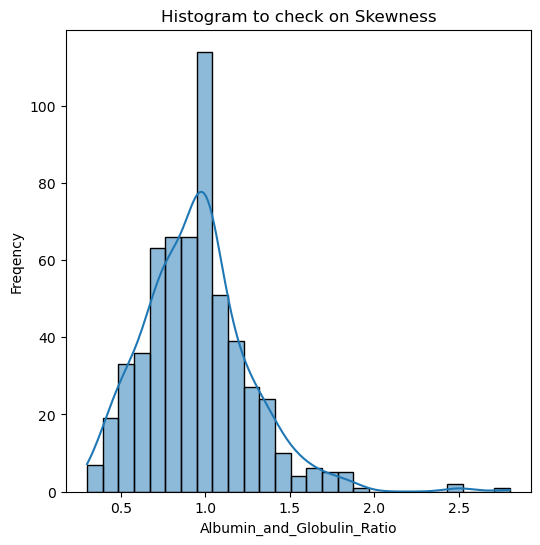

In [12]:
plt.figure(figsize=(6,6))
sns.histplot(liver_patients['Albumin_and_Globulin_Ratio'], kde=True)
plt.title("Histogram to check on Skewness")
plt.xlabel("Albumin_and_Globulin_Ratio")
plt.ylabel("Freqency")
plt.show()

In [13]:
liver_patients['Albumin_and_Globulin_Ratio'] = liver_patients['Albumin_and_Globulin_Ratio'].fillna(liver_patients['Albumin_and_Globulin_Ratio'].median())

### cheack missing value

In [14]:
liver_patients.isnull().sum()

Age                           0
Gender                        0
Total_Bilirubin               0
Direct_Bilirubin              0
Alkaline_Phosphotase          0
Alamine_Aminotransferase      0
Aspartate_Aminotransferase    0
Total_Protiens                0
Albumin                       0
Albumin_and_Globulin_Ratio    0
Diagnosis                     0
dtype: int64

### count how many duplication 

In [15]:
liver_patients.duplicated().sum()

13

### show how many duplicated records

In [16]:
liver_patients[liver_patients.duplicated(keep=False)]

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Diagnosis
18,40,Female,0.9,0.3,293,232,245,6.8,3.1,0.80,1
19,40,Female,0.9,0.3,293,232,245,6.8,3.1,0.80,1
25,34,Male,4.1,2.0,289,875,731,5.0,2.7,1.10,1
26,34,Male,4.1,2.0,289,875,731,5.0,2.7,1.10,1
33,38,Female,2.6,1.2,410,59,57,5.6,3.0,0.80,2
34,38,Female,2.6,1.2,410,59,57,5.6,3.0,0.80,2
54,42,Male,8.9,4.5,272,31,61,5.8,2.0,0.50,1
55,42,Male,8.9,4.5,272,31,61,5.8,2.0,0.50,1
61,58,Male,1.0,0.5,158,37,43,7.2,3.6,1.00,1
62,58,Male,1.0,0.5,158,37,43,7.2,3.6,1.00,1


### Drop the duplications

In [17]:
liver_patients.drop_duplicates(inplace=True)

### Make sure there is no more duplication in data

In [18]:
liver_patients.duplicated().sum()

0

### Categorical data encoding 

In [19]:
label_encoder = LabelEncoder()
liver_patients['Gender'] = label_encoder.fit_transform(liver_patients['Gender'])

### Check wether the encoding is done correctly

In [20]:
liver_patients.info()

<class 'pandas.core.frame.DataFrame'>
Index: 570 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         570 non-null    int64  
 1   Gender                      570 non-null    int32  
 2   Total_Bilirubin             570 non-null    float64
 3   Direct_Bilirubin            570 non-null    float64
 4   Alkaline_Phosphotase        570 non-null    int64  
 5   Alamine_Aminotransferase    570 non-null    int64  
 6   Aspartate_Aminotransferase  570 non-null    int64  
 7   Total_Protiens              570 non-null    float64
 8   Albumin                     570 non-null    float64
 9   Albumin_and_Globulin_Ratio  570 non-null    float64
 10  Diagnosis                   570 non-null    int64  
dtypes: float64(5), int32(1), int64(5)
memory usage: 51.2 KB


In [21]:
liver_patients.head()

,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Diagnosis
0,65,0,0.7,0.1,187,16,18,6.8,3.3,0.90,1
1,62,1,10.9,5.5,699,64,100,7.5,3.2,0.74,1
2,62,1,7.3,4.1,490,60,68,7.0,3.3,0.89,1
3,58,1,1.0,0.4,182,14,20,6.8,3.4,1.00,1
4,72,1,3.9,2.0,195,27,59,7.3,2.4,0.40,1



In this step, we ensure that the numerical columns in the DataFrame have the correct data types.

Some columns are read as float64 even though all their values 

In [22]:
def convert_column_types(liver_patients):
    for column in liver_patients.columns:
        # Check for float64 columns
        if liver_patients[column].dtype == 'float64':
            if all(liver_patients[column].dropna() % 1 == 0):
                liver_patients[column] = liver_patients[column].astype('int64')
            else:
                liver_patients[column] = liver_patients[column].astype('float64')
        # Check for int32 columns
        elif liver_patients[column].dtype == 'int32':
            liver_patients[column] = liver_patients[column].astype('int64') 
    return liver_patients

liver_patients = convert_column_types(liver_patients)

### Check on the data types corrections

In [23]:
liver_patients.info()

<class 'pandas.core.frame.DataFrame'>
Index: 570 entries, 0 to 582
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Age                         570 non-null    int64  
 1   Gender                      570 non-null    int64  
 2   Total_Bilirubin             570 non-null    float64
 3   Direct_Bilirubin            570 non-null    float64
 4   Alkaline_Phosphotase        570 non-null    int64  
 5   Alamine_Aminotransferase    570 non-null    int64  
 6   Aspartate_Aminotransferase  570 non-null    int64  
 7   Total_Protiens              570 non-null    float64
 8   Albumin                     570 non-null    float64
 9   Albumin_and_Globulin_Ratio  570 non-null    float64
 10  Diagnosis                   570 non-null    int64  
dtypes: float64(5), int64(6)
memory usage: 53.4 KB


# **Statistic Methods**
-----------
Ghaida 

### Descriptive statistics

In [24]:
liver_patients.mean(numeric_only=True)
liver_patients.median(numeric_only=True)
liver_patients.std(numeric_only=True)

Age                            16.242182
Gender                          0.430829
Total_Bilirubin                 6.267941
Direct_Bilirubin                2.833231
Alkaline_Phosphotase          245.291859
Alamine_Aminotransferase      181.471697
Aspartate_Aminotransferase    290.880671
Total_Protiens                  1.088300
Albumin                         0.796813
Albumin_and_Globulin_Ratio      0.318513
Diagnosis                       0.453097
dtype: float64

In [25]:
liver_patients['Gender'].value_counts()
liver_patients['Diagnosis'].value_counts()


Diagnosis
1    406
2    164
Name: count, dtype: int64

In [26]:
liver_patients.corr(numeric_only=True)


,Age,Gender,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio,Diagnosis
Age,1.000000,0.058237,0.011500,0.007050,0.081673,-0.083383,-0.016753,-0.197052,-0.271170,-0.215506,-0.138093
Gender,0.058237,1.000000,0.090298,0.101730,-0.023014,0.084317,0.081497,-0.085895,-0.091369,-0.005343,-0.078501
Total_Bilirubin,0.011500,0.090298,1.000000,0.874116,0.206239,0.217471,0.238678,-0.008588,-0.224124,-0.207474,-0.224430
Direct_Bilirubin,0.007050,0.101730,0.874116,1.000000,0.234609,0.237450,0.258489,-0.000875,-0.230751,-0.201228,-0.250666
Alkaline_Phosphotase,0.081673,-0.023014,0.206239,0.234609,1.000000,0.126830,0.167230,-0.030048,-0.168318,-0.235848,-0.187560
Alamine_Aminotransferase,-0.083383,0.084317,0.217471,0.237450,0.126830,1.000000,0.791857,-0.035193,-0.027973,-0.006394,-0.161917
Aspartate_Aminotransferase,-0.016753,0.081497,0.238678,0.258489,0.167230,0.791857,1.000000,-0.022000,-0.085180,-0.072783,-0.151101
Total_Protiens,-0.197052,-0.085895,-0.008588,-0.000875,-0.030048,-0.035193,-0.022000,1.000000,0.784731,0.233503,0.037794
Albumin,-0.271170,-0.091369,-0.224124,-0.230751,-0.168318,-0.027973,-0.085180,0.784731,1.000000,0.683854,0.166835
Albumin_and_Globulin_Ratio,-0.215506,-0.005343,-0.207474,-0.201228,-0.235848,-0.006394,-0.072783,0.233503,0.683854,1.000000,0.170345


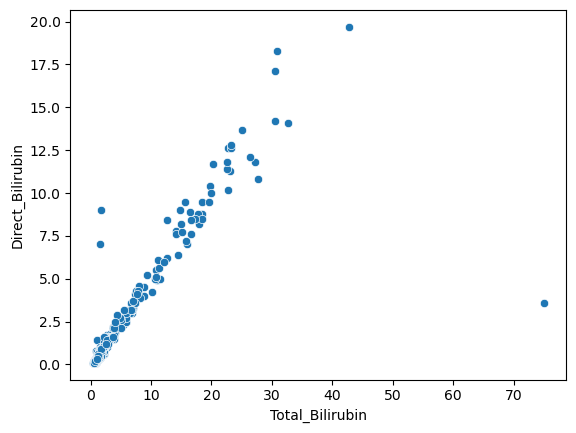

In [27]:
sns.scatterplot(x='Total_Bilirubin', y='Direct_Bilirubin', data=liver_patients)
plt.show()

In [28]:
class StatisticsPlots:

    @staticmethod
    def plot_histograms(liver_patients):
        numeric_df = liver_patients.select_dtypes(include=['int64', 'float64'])
        numeric_df.hist(figsize=(12, 10), bins=20)
        plt.tight_layout()
        plt.show()


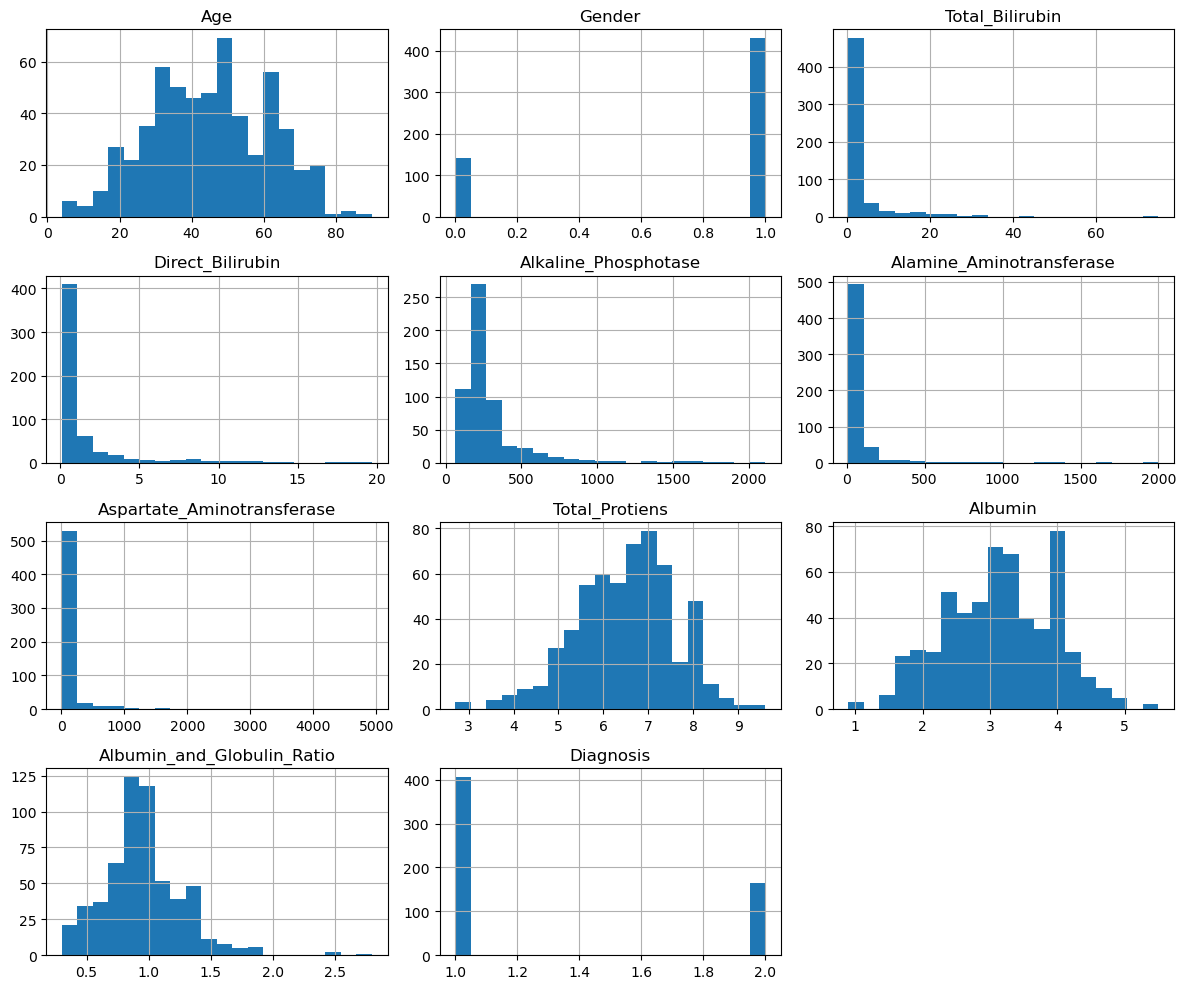

In [29]:
StatisticsPlots.plot_histograms(liver_patients)

# **Outlier Analysis** 
-----------
Reef

 ### Selecting Numeric Columns for Outlier Analysis

In [30]:
# We focus on continuous numeric features and exclude the target and encoded categorical features
numeric_cols = [
    col for col in liver_patients.columns
    if liver_patients[col].dtype != 'object' and col not in ['Diagnosis', 'Gender']
]

print("Numeric columns used for outlier analysis:")
print(numeric_cols)

# quick description of these columns
liver_patients[numeric_cols].describe()

Numeric columns used for outlier analysis:
['Age', 'Total_Bilirubin', 'Direct_Bilirubin', 'Alkaline_Phosphotase', 'Alamine_Aminotransferase', 'Aspartate_Aminotransferase', 'Total_Protiens', 'Albumin', 'Albumin_and_Globulin_Ratio']


,Age,Total_Bilirubin,Direct_Bilirubin,Alkaline_Phosphotase,Alamine_Aminotransferase,Aspartate_Aminotransferase,Total_Protiens,Albumin,Albumin_and_Globulin_Ratio
count,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000,570.000000
mean,44.849123,3.321754,1.497544,291.750877,79.728070,109.380702,6.496316,3.148947,0.947877
std,16.242182,6.267941,2.833231,245.291859,181.471697,290.880671,1.088300,0.796813,0.318513
min,4.000000,0.400000,0.100000,63.000000,10.000000,10.000000,2.700000,0.900000,0.300000
25%,33.000000,0.800000,0.200000,176.000000,23.000000,25.000000,5.800000,2.600000,0.700000
50%,45.000000,1.000000,0.300000,208.000000,35.000000,41.000000,6.600000,3.100000,0.930000
75%,58.000000,2.600000,1.300000,298.000000,60.000000,86.750000,7.200000,3.800000,1.100000
max,90.000000,75.000000,19.700000,2110.000000,2000.000000,4929.000000,9.600000,5.500000,2.800000


### Visualizing Potential Outliers with Boxplots

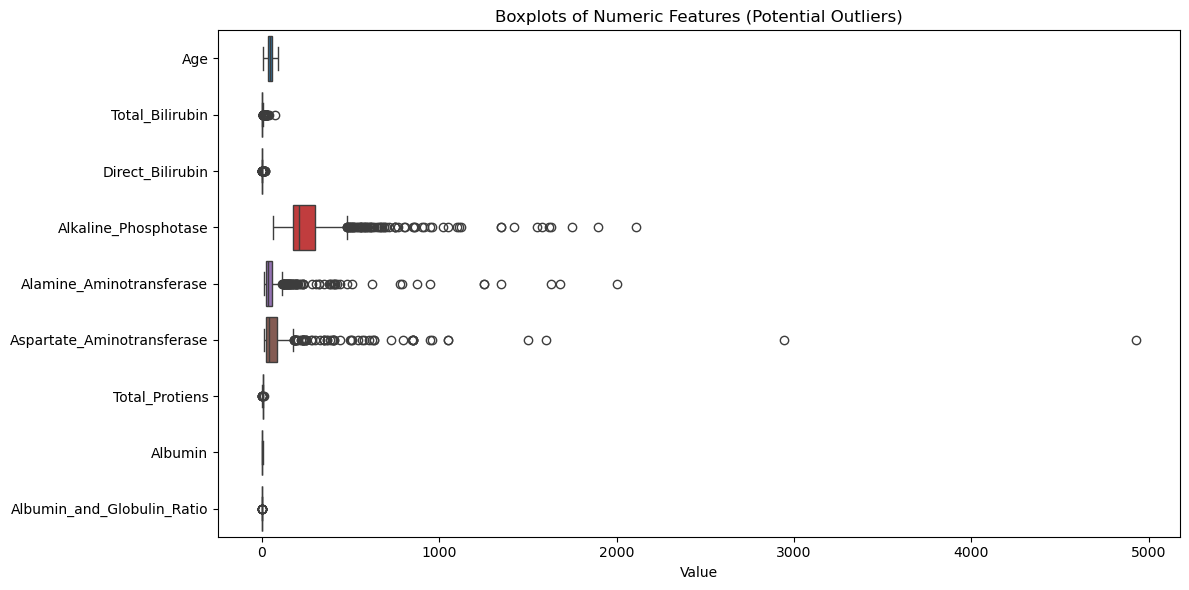

In [31]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=liver_patients[numeric_cols], orient='h')
plt.title("Boxplots of Numeric Features (Potential Outliers)")
plt.xlabel("Value")
plt.tight_layout()
plt.show()



### IQR-Based Outlier Detection

In [32]:
iqr_outlier_mask = pd.Series(False, index=liver_patients.index)   # row-wise flag for "any IQR outlier"
iqr_outliers_per_col = {}                             # store counts per column

for col in numeric_cols:
    data_col = liver_patients[col]

    Q1 = data_col.quantile(0.25)
    Q3 = data_col.quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # mask of outliers in this column
    col_mask = (data_col < lower_bound) | (data_col > upper_bound)
    iqr_outliers_per_col[col] = col_mask.sum()

    # update global mask (row is outlier if any column is outlier)
    iqr_outlier_mask |= col_mask

    print(f"{col}: {col_mask.sum()} IQR outliers (lower={lower_bound:.2f}, upper={upper_bound:.2f})")

n_iqr_outliers = iqr_outlier_mask.sum()
print("\nTotal rows flagged as outliers by IQR (any numeric feature):", n_iqr_outliers)

df_iqr_outliers = liver_patients[iqr_outlier_mask]


Age: 0 IQR outliers (lower=-4.50, upper=95.50)
Total_Bilirubin: 83 IQR outliers (lower=-1.90, upper=5.30)
Direct_Bilirubin: 80 IQR outliers (lower=-1.45, upper=2.95)
Alkaline_Phosphotase: 69 IQR outliers (lower=-7.00, upper=481.00)
Alamine_Aminotransferase: 72 IQR outliers (lower=-32.50, upper=115.50)
Aspartate_Aminotransferase: 66 IQR outliers (lower=-67.62, upper=179.38)
Total_Protiens: 8 IQR outliers (lower=3.70, upper=9.30)
Albumin: 0 IQR outliers (lower=0.80, upper=5.60)
Albumin_and_Globulin_Ratio: 10 IQR outliers (lower=0.10, upper=1.70)

Total rows flagged as outliers by IQR (any numeric feature): 183


### Outlier Summary

In [33]:
total_rows = len(liver_patients)

summary = pd.DataFrame({
    "Method": ["IQR (per feature)"],
    "Number_of_Outliers": [n_iqr_outliers]
})

summary["Percentage_of_Dataset_%"] = (
    summary["Number_of_Outliers"] / total_rows * 100
).round(2)

summary


,Method,Number_of_Outliers,Percentage_of_Dataset_%
0,IQR (per feature),183,32.11


### Creating a Cleaned Dataset for Modeling

In [34]:
# Create a cleaned dataset using only the IQR mask
liver_patients_no_outliers = liver_patients[~iqr_outlier_mask].copy()

print("Original dataset size:", liver_patients.shape)
print("Rows removed (IQR outliers):", iqr_outlier_mask.sum())
print("Cleaned dataset size:", liver_patients_no_outliers.shape)


Original dataset size: (570, 11)
Rows removed (IQR outliers): 183
Cleaned dataset size: (387, 11)


# **Cont. Data Cleaning and Preprocessing**
-----------
Zinab Mukhtar & Hedah 

### Split data and Target

In [35]:
liver_patients['Diagnosis'] = liver_patients['Diagnosis'].map({1: 1, 2: 0})


In [36]:
X = liver_patients.drop('Diagnosis', axis=1) 
y = liver_patients['Diagnosis']

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Data scalling

In [38]:
scaler = RobustScaler()
X_train_scale = scaler.fit_transform(X_train)
X_test_scale = scaler.transform(X_test)

# **Logistic Regression**
-----------
Nahida

### Initializing the Logistic Regression model

In [39]:
LogisticRegression_Model = LogisticRegression(random_state=42, max_iter=1000)

### Training the Logistic Regression model

In [40]:
LogisticRegression_Model.fit(X_train_scale, y_train)

LogisticRegression(max_iter=1000, random_state=42)

### Predict the test set labels

In [41]:
y_pred_log = LogisticRegression_Model.predict(X_test_scale)
y_pred_log

array([1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 0, 1, 0], dtype=int64)

### Predicting Probabilities

In [42]:
y_prob_log = LogisticRegression_Model.predict_proba(X_test_scale)[:, 1]
y_prob_log

array([0.84606116, 0.58121031, 0.43038226, 0.55027757, 0.74946467,
       0.76468001, 0.64024539, 0.55148697, 0.47269846, 0.60676864,
       0.50643952, 0.61066638, 0.60376324, 0.56479054, 0.58564286,
       0.64875113, 0.59187957, 0.99949174, 0.62836712, 0.66416912,
       0.56270021, 0.61950254, 0.99506865, 0.84522593, 0.7484745 ,
       0.43604215, 0.76699733, 0.98703444, 0.77513716, 0.95984988,
       0.55312614, 0.98169432, 0.78427919, 0.99947676, 0.61004522,
       0.5781102 , 0.68479253, 0.65874892, 0.45939946, 0.67144498,
       0.84887491, 0.4892056 , 0.43473776, 0.76400043, 0.50228343,
       0.94777903, 0.99989169, 0.82211509, 0.98332604, 0.48014334,
       0.62175653, 0.54467024, 0.99929763, 0.72984143, 0.42075469,
       0.87017559, 0.53282659, 0.65107315, 0.95145979, 0.95366816,
       0.48153129, 0.97544359, 0.81500747, 0.93276757, 0.5682897 ,
       0.99999795, 0.71496848, 0.92989076, 0.79884708, 0.58107277,
       0.80250286, 0.85997296, 0.74833965, 0.68040746, 0.40407

### ROC Curve

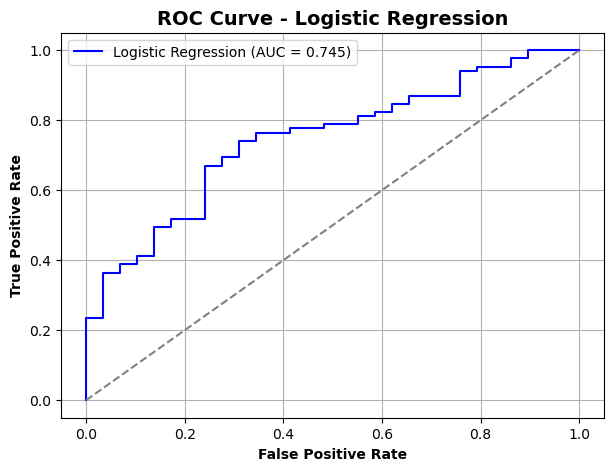

In [43]:
fpr_log, tpr_log, thresholds_log = roc_curve(y_test, y_prob_log)

auc_log = roc_auc_score(y_test, y_prob_log)


plt.figure(figsize=(7,5))
plt.plot(fpr_log, tpr_log, color='blue', label=f'Logistic Regression (AUC = {auc_log:.3f})')
plt.plot([0,1], [0,1], color='gray', linestyle='--')  
plt.title('ROC Curve - Logistic Regression', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.legend()
plt.grid(True)
plt.show()

### Evaluate the model 

In [44]:
accuracy_score_log = accuracy_score(y_test, y_pred_log)
confusion_matrix_log = confusion_matrix(y_test, y_pred_log)
classification_report_log = classification_report(y_test, y_pred_log, target_names=['No Disease', 'Disease'])

print(f"Logistic Regression Accuracy:  {accuracy_score_log}  {accuracy_score_log*100:.2f}%  ")
print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix_log)
print("\nLogistic Regression Classification Report:")
print(classification_report_log)

Logistic Regression Accuracy:  0.7280701754385965  72.81%  

Logistic Regression Confusion Matrix:
[[ 7 22]
 [ 9 76]]

Logistic Regression Classification Report:
              precision    recall  f1-score   support

  No Disease       0.44      0.24      0.31        29
     Disease       0.78      0.89      0.83        85

    accuracy                           0.73       114
   macro avg       0.61      0.57      0.57       114
weighted avg       0.69      0.73      0.70       114



### Confusion Matrix Visualization

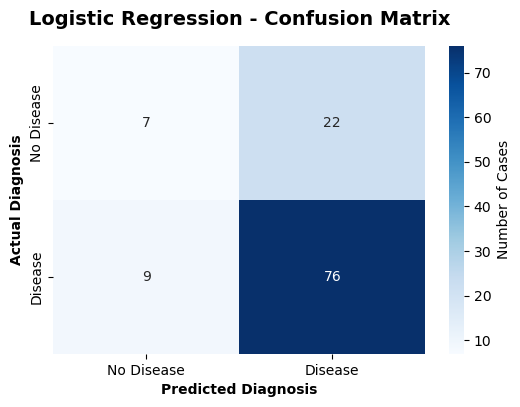

In [45]:
cm = confusion_matrix(y_test, y_pred_log)
cm
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'],
            cbar_kws={'label': 'Number of Cases'})
plt.xlabel('Predicted Diagnosis', fontweight='bold')
plt.ylabel('Actual Diagnosis', fontweight='bold')
plt.title("Logistic Regression - Confusion Matrix", fontsize=14, fontweight='bold', pad=15)
plt.show()

# **Decision Tree**
-----------
Zainab Hassan

### Initializing the Decision Tree model

In [46]:
DecisionTree_Model = DecisionTreeClassifier(max_depth=9, random_state=1)

### Fit dt to the training set 

In [47]:
DecisionTree_Model.fit(X_train,y_train)

DecisionTreeClassifier(max_depth=9, random_state=1)

### Predict the test set labels

In [48]:
y_pred_dt = DecisionTree_Model.predict(X_test)
y_pred_dt

array([1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 1, 1], dtype=int64)

### Predicting Probabilities

In [49]:
y_prob_dt = DecisionTree_Model.predict_proba(X_test)[:, 1]
y_prob_dt

array([1.        , 0.56603774, 1.        , 0.56603774, 1.        ,
       1.        , 0.56603774, 0.56603774, 0.        , 0.56603774,
       0.56603774, 0.56603774, 0.56603774, 1.        , 0.56603774,
       0.        , 1.        , 1.        , 0.        , 0.56603774,
       0.        , 0.56603774, 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 1.        , 1.        ,
       0.        , 1.        , 1.        , 1.        , 0.56603774,
       0.56603774, 0.56603774, 1.        , 0.56603774, 1.        ,
       1.        , 0.56603774, 0.        , 0.56603774, 0.56603774,
       1.        , 1.        , 0.56603774, 1.        , 0.56603774,
       0.56603774, 0.56603774, 1.        , 0.        , 0.        ,
       1.        , 0.56603774, 0.        , 0.        , 1.        ,
       0.56603774, 1.        , 1.        , 1.        , 1.        ,
       1.        , 0.        , 1.        , 1.        , 1.        ,
       1.        , 1.        , 1.        , 0.        , 0.     

### Decision Tree Visualization

[Text(0.6137971698113207, 0.95, 'x[2] <= 1.65\ngini = 0.417\nsamples = 456\nvalue = [135, 321]'),
 Text(0.41627358490566035, 0.85, 'x[5] <= 66.5\ngini = 0.487\nsamples = 291\nvalue = [122, 169]'),
 Text(0.5150353773584906, 0.8999999999999999, 'True  '),
 Text(0.24764150943396226, 0.75, 'x[0] <= 22.5\ngini = 0.497\nsamples = 255\nvalue = [118, 137]'),
 Text(0.11320754716981132, 0.65, 'x[6] <= 42.5\ngini = 0.428\nsamples = 29\nvalue = [20, 9]'),
 Text(0.07547169811320754, 0.55, 'x[8] <= 4.75\ngini = 0.308\nsamples = 21\nvalue = [17, 4]'),
 Text(0.05660377358490566, 0.45, 'x[2] <= 1.45\ngini = 0.255\nsamples = 20\nvalue = [17, 3]'),
 Text(0.03773584905660377, 0.35, 'x[0] <= 20.5\ngini = 0.188\nsamples = 19\nvalue = [17, 2]'),
 Text(0.018867924528301886, 0.25, 'gini = 0.0\nsamples = 12\nvalue = [12, 0]'),
 Text(0.05660377358490566, 0.25, 'x[3] <= 0.15\ngini = 0.408\nsamples = 7\nvalue = [5, 2]'),
 Text(0.03773584905660377, 0.15, 'gini = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.075471698

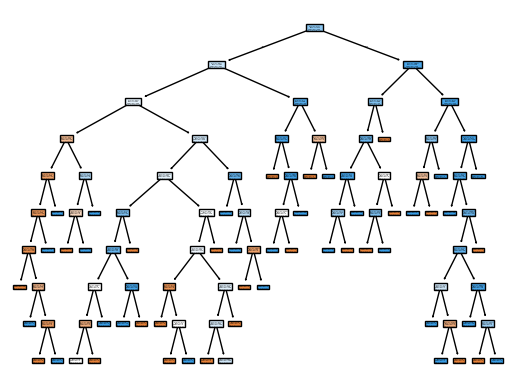

In [50]:
tree.plot_tree(DecisionTree_Model, filled=True)

### ROC Curve

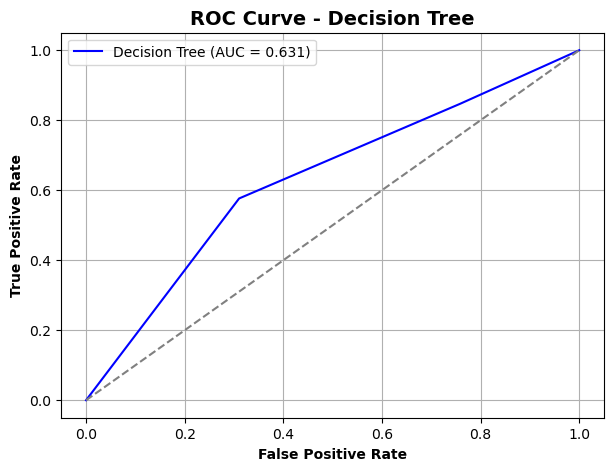

In [51]:
fpr_dt, tpr_dt, thresholds_dt = roc_curve(y_test, y_prob_dt)

auc_dt = roc_auc_score(y_test, y_prob_dt)


plt.figure(figsize=(7,5))
plt.plot(fpr_dt, tpr_dt, color='blue', label=f'Decision Tree (AUC = {auc_dt:.3f})')
plt.plot([0,1], [0,1], color='gray', linestyle='--')  
plt.title('ROC Curve - Decision Tree', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.legend()
plt.grid(True)
plt.show()


### Evaluate the model 

In [52]:
accuracy_score_dt = accuracy_score(y_test, y_pred_dt)
confusion_matrix_dt = confusion_matrix(y_test, y_pred_dt)
classification_report_dt = classification_report(y_test, y_pred_dt, target_names=['No Disease', 'Disease'])

print(f"Decision Tree Accuracy:  {accuracy_score_dt}  {accuracy_score_dt*100:.2f}%  ")
print("\nDecision Tree Confusion Matrix:")
print(confusion_matrix_dt)
print("\nDecision Tree Classification Report:")
print(classification_report_dt)

Decision Tree Accuracy:  0.6929824561403509  69.30%  

Decision Tree Confusion Matrix:
[[ 7 22]
 [13 72]]

Decision Tree Classification Report:
              precision    recall  f1-score   support

  No Disease       0.35      0.24      0.29        29
     Disease       0.77      0.85      0.80        85

    accuracy                           0.69       114
   macro avg       0.56      0.54      0.55       114
weighted avg       0.66      0.69      0.67       114



### Confusion Matrix Visualization

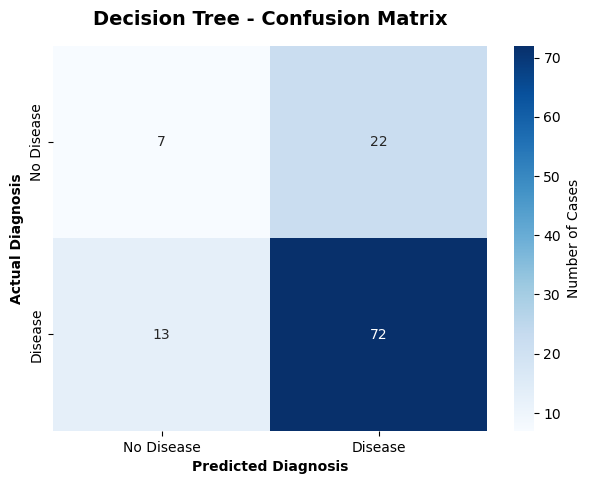

In [53]:
plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'],
            cbar_kws={'label': 'Number of Cases'})

plt.title('Decision Tree - Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Diagnosis', fontweight='bold')
plt.ylabel('Actual Diagnosis', fontweight='bold')

plt.show()

# **Random Forest**
-----------
Donia

### Initialize the Random Forest Classifier

In [54]:
RandomForest_Model = RandomForestClassifier(random_state=42, n_estimators=100)

### Fit the model

In [55]:
RandomForest_Model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

### Predict the test set labels

In [56]:
y_pred_rf = RandomForest_Model.predict(X_test)
y_pred_rf

array([1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 0, 1,
       0, 1, 1, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1,
       1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1,
       1, 0, 0, 0], dtype=int64)

### Predicting Probabilities

In [57]:
y_prob_rf = RandomForest_Model.predict_proba(X_test)[:, 1]
y_prob_rf

array([0.75, 0.48, 0.64, 0.62, 0.86, 0.9 , 0.59, 0.65, 0.54, 0.45, 0.44,
       0.7 , 0.61, 0.7 , 0.53, 0.52, 0.66, 0.87, 0.57, 0.63, 0.51, 0.55,
       0.97, 0.91, 0.59, 0.63, 0.92, 0.98, 0.81, 0.89, 0.61, 0.82, 0.84,
       0.91, 0.41, 0.44, 0.66, 0.79, 0.49, 0.77, 0.94, 0.64, 0.32, 0.7 ,
       0.41, 0.85, 0.97, 0.65, 0.94, 0.33, 0.67, 0.33, 0.99, 0.71, 0.36,
       0.75, 0.71, 0.82, 0.98, 0.93, 0.46, 0.94, 0.52, 0.95, 0.73, 1.  ,
       0.51, 0.9 , 0.5 , 0.82, 0.91, 0.98, 0.88, 0.45, 0.3 , 0.57, 0.85,
       0.51, 0.87, 0.55, 0.49, 0.88, 1.  , 0.6 , 0.35, 0.96, 0.76, 0.64,
       0.51, 0.75, 1.  , 0.71, 0.74, 0.68, 0.89, 0.95, 0.79, 0.4 , 0.77,
       0.58, 0.65, 0.67, 0.69, 0.46, 0.94, 0.4 , 0.61, 0.81, 0.99, 0.93,
       0.84, 0.49, 0.37, 0.44])

### ROC Curve

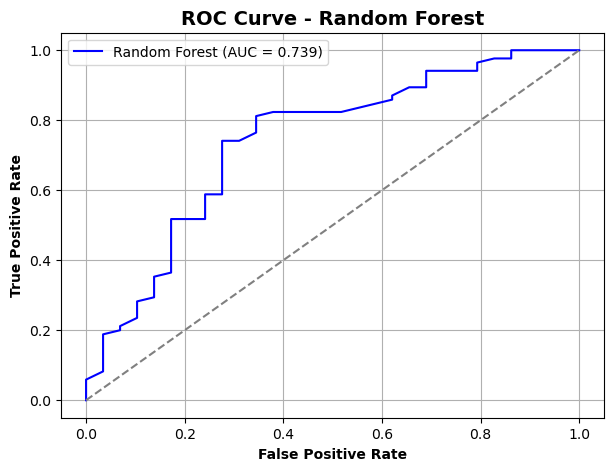

In [58]:
# ROC and AUC for Random Forest
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_prob_rf)

auc_rf = roc_auc_score(y_test, y_prob_rf)


plt.figure(figsize=(7,5))
plt.plot(fpr_rf, tpr_rf, color='blue', label=f'Random Forest (AUC = {auc_rf:.3f})')
plt.plot([0,1], [0,1], color='gray', linestyle='--')  
plt.title('ROC Curve - Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('False Positive Rate', fontweight='bold')
plt.ylabel('True Positive Rate', fontweight='bold')
plt.legend()
plt.grid(True)
plt.show()

### Evaluate the model 

In [59]:
# Evaluate Random Forest Classifier
accuracy_score_rf = accuracy_score(y_test, y_pred_rf)
confusion_matrix_rf = confusion_matrix(y_test, y_pred_rf)
classification_report_rf = classification_report(y_test, y_pred_rf, target_names=['No Disease', 'Disease'])

print(f"Random Forest Classifier Accuracy:  {accuracy_score_rf}  {accuracy_score_rf*100:.2f}%  ")
print("\nRandom Forest Classifier Confusion Matrix:")
print(confusion_matrix_rf)
print("\nRandom Forest Classifier Classification Report:")
print(classification_report_rf)


Random Forest Classifier Accuracy:  0.7368421052631579  73.68%  

Random Forest Classifier Confusion Matrix:
[[11 18]
 [12 73]]

Random Forest Classifier Classification Report:
              precision    recall  f1-score   support

  No Disease       0.48      0.38      0.42        29
     Disease       0.80      0.86      0.83        85

    accuracy                           0.74       114
   macro avg       0.64      0.62      0.63       114
weighted avg       0.72      0.74      0.73       114



### Confusion Matrix Visualization

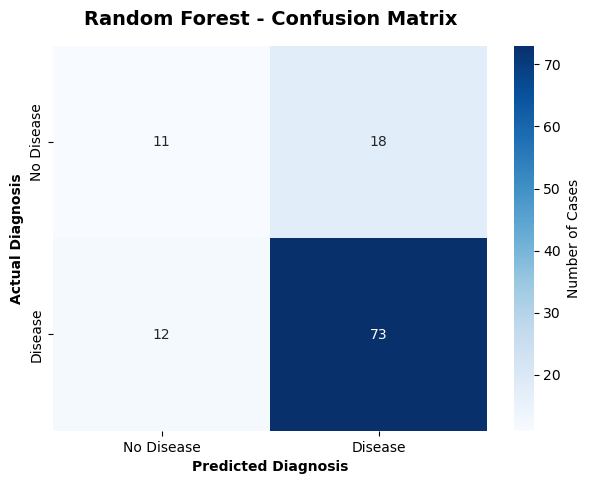

In [60]:
# Confusion Matrix for Random Forest Classifier

plt.figure(figsize=(7,5))
sns.heatmap(confusion_matrix_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Disease', 'Disease'],
            yticklabels=['No Disease', 'Disease'],
            cbar_kws={'label': 'Number of Cases'})

plt.title('Random Forest - Confusion Matrix', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Predicted Diagnosis', fontweight='bold')
plt.ylabel('Actual Diagnosis', fontweight='bold')

plt.show()


## *Models Tuning*

### Logistic Regression

In [77]:

# Hyperparameter tuning
params = {
    "penalty": ["l1", "l2"],
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["liblinear"]
}

grid = GridSearchCV(
    LogisticRegression(max_iter=1000),
    params,
    cv=5,
    scoring="accuracy"
)

In [78]:
grid.fit(X_train_scale, y_train)
best_model = grid.best_estimator_

In [ ]:

y_pred_tuned = best_model.predict(X_test_scale)

In [80]:
# Evaluation
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)
class_report_tuned = classification_report(y_test, y_pred_tuned)
conf_matrix_tuned = confusion_matrix(y_test, y_pred_tuned)

print("Tuned Accuracy:", accuracy_tuned)
print("\nClassification Report:\n", class_report_tuned)
print("\nConfusion Matrix:\n", conf_matrix_tuned)


Tuned Accuracy: 0.7192982456140351

Classification Report:
               precision    recall  f1-score   support

           0       0.42      0.28      0.33        29
           1       0.78      0.87      0.82        85

    accuracy                           0.72       114
   macro avg       0.60      0.57      0.58       114
weighted avg       0.69      0.72      0.70       114


Confusion Matrix:
 [[ 8 21]
 [11 74]]


### Decision Trees

In [81]:
# Define the Decision Tree model
dt_model = DecisionTreeClassifier()

In [82]:
param_grid = {
    'max_depth': [None, 10, 20, 30],  # Tree depth
    'min_samples_split': [2, 5, 10],  # Minimum samples required to split a node
    'min_samples_leaf': [1, 2, 4],  # Minimum samples required at leaf node
    'max_features': ['sqrt', 'log2', None]  # Corrected 'auto' to valid values
}


In [83]:
# Setup GridSearchCV for hyperparameter tuning
grid_search_dt = GridSearchCV(estimator=dt_model, param_grid=param_grid, cv=5, n_jobs=-1, verbose=2)

In [84]:
# Train the model using GridSearchCV
grid_search_dt.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


GridSearchCV(cv=5, estimator=DecisionTreeClassifier(), n_jobs=-1,
             param_grid={'max_depth': [None, 10, 20, 30],
                         'max_features': ['sqrt', 'log2', None],
                         'min_samples_leaf': [1, 2, 4],
                         'min_samples_split': [2, 5, 10]},
             verbose=2)

In [85]:
# Print the best parameters found by GridSearchCV
print("=== Tuned Decision Tree ===")
print("Best Parameters:", grid_search_dt.best_params_)

# Get the best model after tuning
best_dt = grid_search_dt.best_estimator_

# Make predictions using the tuned model
y_pred_dt = best_dt.predict(X_test)

# Evaluate the model's performance
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print(classification_report(y_test, y_pred_dt))

=== Tuned Decision Tree ===
Best Parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 2, 'min_samples_split': 5}
Accuracy: 0.6842105263157895
              precision    recall  f1-score   support

           0       0.41      0.59      0.49        29
           1       0.84      0.72      0.77        85

    accuracy                           0.68       114
   macro avg       0.63      0.65      0.63       114
weighted avg       0.73      0.68      0.70       114



### Random Forests 

In [86]:
param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [4, 6, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 'log2', None]
}

rf = RandomForestClassifier(random_state=42)
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid,
                           cv=5, scoring='accuracy', n_jobs=-1, verbose=2) 

In [87]:
grid_search.fit(X_train, y_train)
best_rf = grid_search.best_estimator_

Fitting 5 folds for each of 72 candidates, totalling 360 fits


In [88]:
print("=== Tuned Random Forest ===")
print("Best Parameters:", grid_search.best_params_)

y_pred_rf = best_rf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf))

=== Tuned Random Forest ===
Best Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Accuracy: 0.7368421052631579
              precision    recall  f1-score   support

           0       0.48      0.38      0.42        29
           1       0.80      0.86      0.83        85

    accuracy                           0.74       114
   macro avg       0.64      0.62      0.63       114
weighted avg       0.72      0.74      0.73       114



### Feature importance 

In [89]:
# 1. Create a pd.Series of feature importances
importances_rf = pd.Series(RandomForest_Model.feature_importances_, index = X.columns)

In [90]:
# 2. Sort importances_rf
sorted_importances_rf = importances_rf.sort_values()


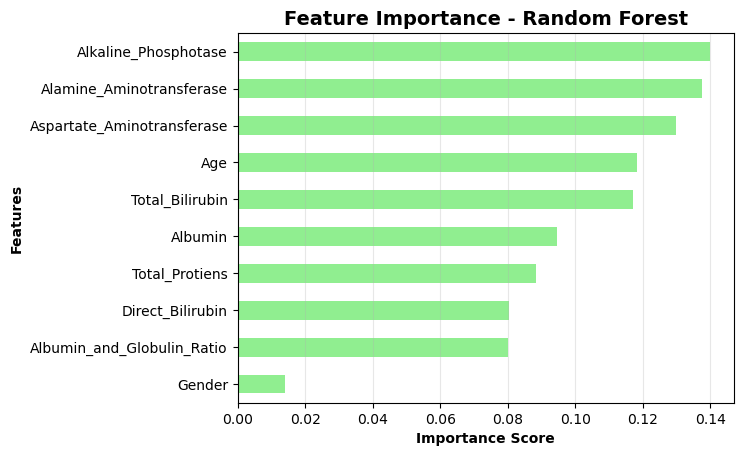

In [91]:
# 3. Make a horizontal bar plot
sorted_importances_rf.plot(kind='barh', color='lightgreen')
plt.title('Feature Importance - Random Forest', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score', fontweight='bold')
plt.ylabel('Features', fontweight='bold')
plt.grid(True, axis='x', alpha=0.3)
plt.show()


In [92]:
# 4. Display the actual importance values
print("Feature Importance Scores (Random Forest):")
print(sorted_importances_rf)

Feature Importance Scores (Random Forest):
Gender                        0.014146
Albumin_and_Globulin_Ratio    0.080145
Direct_Bilirubin              0.080264
Total_Protiens                0.088498
Albumin                       0.094539
Total_Bilirubin               0.117184
Age                           0.118138
Aspartate_Aminotransferase    0.129741
Alamine_Aminotransferase      0.137445
Alkaline_Phosphotase          0.139899
dtype: float64
